# 初回購入のカテゴリと再購入

## 問い

[07_first_purchase_experience.ipynb](07_first_purchase_experience.ipynb) で、初回の購入体験 (配送・レビュー) だけでは、再購入の少なさを説明できないことがわかった。
次に、**購入した商品そのものの違い**に着目する。

| 確認すること | 問い |
|---|---|
| 初回購入のカテゴリ別の 90 日以内の再購入率 | 再購入しやすいカテゴリはどこか |
| カテゴリ別の再購入までの日数 | 再購入のタイミングはカテゴリによって違うか |
| 初回購入と再購入のカテゴリ | 同じカテゴリを買い直すのか、別のカテゴリに広がるのか |

## 定義

再購入と観察期間の定義は、[ADR 013](../docs/decisions/013_repeat_customer_definition.md) と同じ。

- **初回購入のカテゴリ**: 初回購入日の注文 (同時購入を含む) の商品のうち、商品の数が最も多いカテゴリ。同数なら金額の合計が大きい方、さらに同じならカテゴリ名の辞書順で先のもの (`top_category` と同じ考え方。[ADR 007](../docs/decisions/007_customer_feature_principles.md) の原則 4)
- カテゴリ名は英語名を使い、英語名がなければポルトガル語名を使う。カテゴリがない商品は `(unknown)` とする
- **再購入のカテゴリ**: 再購入の日 (初回購入日より後の最初の購入日) の注文の商品のカテゴリの集合
- **同じカテゴリの再購入**: 初回購入のカテゴリが、再購入のカテゴリの集合に含まれる

## 注意

- 顧客が少ないカテゴリは、再購入率が偶然大きく振れる。90 日を観察できる顧客が 1,000 人以上のカテゴリだけを個別に示し、ほかは `(other)` にまとめる。
- ここでわかるのは関連であり、カテゴリが再購入の理由であるとは言えない。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 100)

client = bigquery.Client()  # プロジェクトは gcloud の設定から取得する

# カテゴリは mart に注文単位の列がないため、明細 (staging) から付ける。対象の注文は mart の delivered の注文
ITEMS_QUERY = """
select
    orders.customer_unique_id,
    orders.order_purchase_date,
    items.price,
    coalesce(translation.product_category_name_english, products.product_category_name) as category
from olist_mart.fct_delivered_orders as orders
inner join olist_staging.stg_order_items as items
    on orders.order_id = items.order_id
left join olist_staging.stg_products as products
    on items.product_id = products.product_id
left join olist_staging.stg_product_category_name_translation as translation
    on products.product_category_name = translation.product_category_name
"""
items = client.query(ITEMS_QUERY).to_dataframe()
REFERENCE_DATE = pd.Timestamp(
    client.query("select max(reference_date) as d from olist_mart.customer_features").to_dataframe()["d"].iloc[0]
)
items = items.assign(
    purchase_date=pd.to_datetime(items["order_purchase_date"]),
    price=items["price"].astype("float"),
    category=items["category"].fillna("(unknown)"),
)
items.shape, REFERENCE_DATE

/home/seven/workspace/olist-data-platform/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


/home/seven/workspace/olist-data-platform/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


((110197, 5), Timestamp('2018-08-29 00:00:00'))

## 1. 初回購入のカテゴリと、再購入の日を顧客ごとに求める

In [2]:
items["first_date"] = items.groupby("customer_unique_id")["purchase_date"].transform("min")
first_items = items[items["purchase_date"] == items["first_date"]]
later_items = items[items["purchase_date"] > items["first_date"]]

# 初回購入のカテゴリ: 商品の数の降順 → 金額の合計の降順 → カテゴリ名の昇順で先頭
by_category = (
    first_items.groupby(["customer_unique_id", "category"])
    .agg(item_count=("price", "size"), amount=("price", "sum"))
    .reset_index()
    .sort_values(["customer_unique_id", "item_count", "amount", "category"], ascending=[True, False, False, True])
)
first_category = by_category.drop_duplicates("customer_unique_id").set_index("customer_unique_id")["category"]

customers = pd.DataFrame({
    "first_date": items.groupby("customer_unique_id")["first_date"].first(),
    "first_category": first_category,
    "first_category_count": first_items.groupby("customer_unique_id")["category"].nunique(),
    "next_date": later_items.groupby("customer_unique_id")["purchase_date"].min(),
})
customers["days_to_repurchase"] = (customers["next_date"] - customers["first_date"]).dt.days
customers["observed_days"] = (REFERENCE_DATE - customers["first_date"]).dt.days
customers["purchase_month"] = customers["first_date"].dt.to_period("M")

print(f"顧客: {len(customers):,} 人 / リピーター: {customers['next_date'].notna().sum():,} 人")
print(f"初回購入に複数のカテゴリがある顧客: {(customers['first_category_count'] > 1).sum():,} 人")
print(f"初回購入のカテゴリが (unknown) の顧客: {(customers['first_category'] == '(unknown)').sum():,} 人")

顧客: 93,358 人 / リピーター: 2,015 人
初回購入に複数のカテゴリがある顧客: 1,021 人
初回購入のカテゴリが (unknown) の顧客: 1,319 人


## 2. 初回購入のカテゴリ別の、90 日以内の再購入率

90 日を観察できる顧客 (初回購入日が基準日の 90 日以上前) に絞る。

In [3]:
MIN_CUSTOMERS = 1_000
WINDOW = 90

observable = customers[customers["observed_days"] >= WINDOW].copy()
observable["repurchased"] = observable["days_to_repurchase"] <= WINDOW  # 再購入がなければ NaN のため False

size = observable["first_category"].value_counts()
large = size[size >= MIN_CUSTOMERS].index
observable["category_group"] = observable["first_category"].where(observable["first_category"].isin(large), "(other)")

grouped = observable.groupby("category_group")["repurchased"]
rate = grouped.mean()
n = grouped.size()
se = np.sqrt(rate * (1 - rate) / n)
category_rates = pd.DataFrame({
    "customers": n,
    "repurchased": grouped.sum(),
    "repurchase_rate": rate,
    "ci_low": rate - 1.96 * se,
    "ci_high": rate + 1.96 * se,
}).sort_values("repurchase_rate", ascending=False)

print(f"全体: {observable['repurchased'].mean():.2%} ({len(observable):,} 人)")
print(f"個別に示すカテゴリ: {len(large)} 個 (90 日を観察できる顧客の {size[large].sum() / len(observable):.1%})")
category_rates.round(4)

全体: 1.30% (75,387 人)
個別に示すカテゴリ: 20 個 (90 日を観察できる顧客の 88.1%)


,customers,repurchased,repurchase_rate,ci_low,ci_high
category_group,,,,,
fashion_bags_accessories,1425,32,0.0225,0.0148,0.0301
bed_bath_table,7141,141,0.0197,0.0165,0.0230
sports_leisure,6042,100,0.0166,0.0133,0.0198
furniture_decor,4986,79,0.0158,0.0124,0.0193
pet_shop,1184,18,0.0152,0.0082,0.0222
(other),8949,119,0.0133,0.0109,0.0157
watches_gifts,4028,53,0.0132,0.0096,0.0167
health_beauty,6186,78,0.0126,0.0098,0.0154
telephony,3364,41,0.0122,0.0085,0.0159


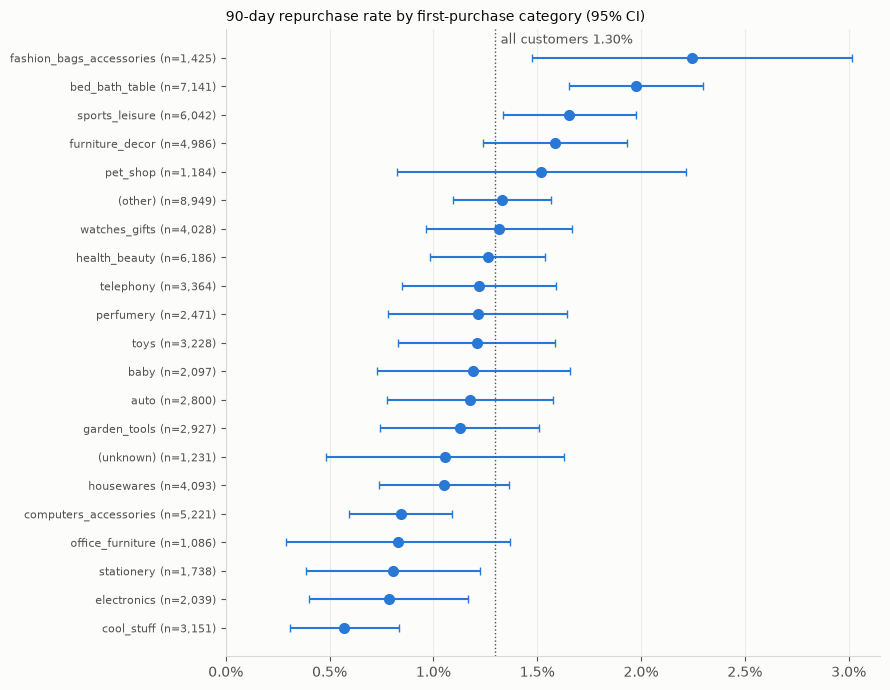

In [4]:
# グラフ内の文字は英語にする (日本語フォントがない環境でも同じように表示するため)
SURFACE = "#fcfcfb"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
SERIES = "#2a78d6"  # 単一系列のため 1 色のみ

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#d9d8d4",
    "axes.labelcolor": TEXT_SECONDARY,
    "axes.titlecolor": TEXT_PRIMARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "axes.grid": True,
    "grid.color": "#ecebe8",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

plot_data = category_rates.sort_values("repurchase_rate")
y = np.arange(len(plot_data))
overall = observable["repurchased"].mean()

fig, ax = plt.subplots(figsize=(9, 7))
ax.errorbar(plot_data["repurchase_rate"], y,
            xerr=[plot_data["repurchase_rate"] - plot_data["ci_low"], plot_data["ci_high"] - plot_data["repurchase_rate"]],
            fmt="o", color=SERIES, markersize=7, capsize=3, linewidth=1.5)
ax.axvline(overall, color=TEXT_SECONDARY, linewidth=1, linestyle=":")
ax.annotate(f"all customers {overall:.2%}", (overall, len(plot_data) - 0.5), xytext=(4, 0),
            textcoords="offset points", fontsize=9, color=TEXT_SECONDARY)
ax.set_yticks(y, [f"{c} (n={n:,})" for c, n in zip(plot_data.index, plot_data["customers"])], fontsize=8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_xlim(left=0)
ax.set_title("90-day repurchase rate by first-purchase category (95% CI)", fontsize=10, loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

### 初回購入の月の構成をそろえた再購入率

カテゴリによって、初回購入の時期の構成が違う可能性がある。各カテゴリの月ごとの再購入率を、全顧客の初回購入月の構成で重み付けして平均する ([06](06_segment_analysis.ipynb)・[07](07_first_purchase_experience.ipynb) と同じ方法)。対象は 2017-01〜 に初回購入した顧客。

In [5]:
in_period = observable[observable["purchase_month"] >= pd.Period("2017-01")]
weights = in_period["purchase_month"].value_counts(normalize=True)
monthly = in_period.groupby(["purchase_month", "category_group"])["repurchased"].mean().unstack("category_group")
w = monthly.notna().mul(weights.reindex(monthly.index), axis=0)
adjusted = monthly.mul(weights.reindex(monthly.index), axis=0).sum() / w.sum()

pd.DataFrame({
    "raw": in_period.groupby("category_group")["repurchased"].mean(),
    "period_adjusted": adjusted,
}).sort_values("period_adjusted", ascending=False).round(4)

,raw,period_adjusted
category_group,,
fashion_bags_accessories,0.0219,0.0208
bed_bath_table,0.0198,0.0198
sports_leisure,0.0166,0.0171
furniture_decor,0.0160,0.0162
pet_shop,0.0153,0.0157
toys,0.0122,0.0137
(other),0.0133,0.0133
watches_gifts,0.0132,0.0131
health_beauty,0.0125,0.0124


### カテゴリ別の再購入率の考察

- 再購入率は、カテゴリによって 0.57% (`cool_stuff`) 〜 2.25% (`fashion_bags_accessories`) と、約 4 倍の差がある。
- 信頼区間が全体の再購入率 (1.30%) と重ならないのは、高い側では `bed_bath_table` (1.97%、7,141 人)、低い側では `computers_accessories` (0.84%) と `cool_stuff` (0.57%)。ほかのカテゴリは、人数に対して差が小さく、全体と区別できない。
- `bed_bath_table` は、初回購入の顧客が最も多いカテゴリでありながら、再購入率も高い。
- 初回購入の月の構成をそろえても、再購入率の大小の順序はほとんど変わらない。カテゴリの差は、購入した時期の違いでは説明できない。
- 大きいカテゴリどうしの差 (`bed_bath_table` 1.97% と `computers_accessories` 0.84% で 約 1.1 ポイント) は、初回の配送の遅延の有無による差 (0.31 ポイント。[07](07_first_purchase_experience.ipynb)) より大きい。

## 3. 初回購入と再購入のカテゴリ

リピーター (観察期間を問わず、再購入したことがある顧客) について、再購入の日に、初回購入と同じカテゴリを買ったかを見る。

In [6]:
repurchase_items = later_items.merge(
    customers["next_date"].dropna().rename("next_date"), left_on="customer_unique_id", right_index=True
)
repurchase_items = repurchase_items[repurchase_items["purchase_date"] == repurchase_items["next_date"]]
repurchase_categories = repurchase_items.groupby("customer_unique_id")["category"].agg(set)

repeaters = customers.loc[repurchase_categories.index, ["first_category", "days_to_repurchase"]].copy()
repeaters["same_category"] = [
    first in second for first, second in zip(repeaters["first_category"], repurchase_categories)
]

print(f"リピーター: {len(repeaters):,} 人")
print(f"再購入で、初回と同じカテゴリを買った割合: {repeaters['same_category'].mean():.1%}")
repeaters.groupby("same_category")["days_to_repurchase"].describe(percentiles=[0.25, 0.5, 0.75]).round(1)

リピーター: 2,015 人
再購入で、初回と同じカテゴリを買った割合: 38.6%


,count,mean,std,min,25%,50%,75%,max
same_category,,,,,,,,
False,1238.0,139.9,120.4,1.0,39.0,113.0,209.0,609.0
True,777.0,74.5,91.7,1.0,14.0,41.0,98.0,511.0


In [7]:
# 再購入までの日数の区分ごとの、同じカテゴリの割合
gap_bins = pd.cut(repeaters["days_to_repurchase"], bins=[0, 15, 30, 90, 180, 700],
                  labels=["1-15", "16-30", "31-90", "91-180", "181+"])
repeaters.groupby(gap_bins, observed=True)["same_category"].agg(["size", "mean"]).round(3)

,size,mean
days_to_repurchase,,
1-15,383,0.548
16-30,217,0.585
31-90,507,0.460
91-180,423,0.270
181+,485,0.192


- 再購入で、初回と同じカテゴリを買ったリピーターは 38.6%。6 割は、別のカテゴリを買っている。
- 同じカテゴリの再購入は、早く起きる (再購入までの日数の中央値 41 日。別のカテゴリは 113 日)。
- 初回から 30 日以内の再購入では、半分以上 (55〜59%) が同じカテゴリ。181 日以上あとの再購入では、19% にとどまる。

### カテゴリ別の、同じカテゴリの割合と再購入までの日数

リピーターが 30 人以上いるカテゴリだけを示す (人数が少ないため、目安として見る)。

In [8]:
by_first = repeaters.groupby("first_category").agg(
    repeaters=("same_category", "size"),
    same_category_rate=("same_category", "mean"),
    days_median=("days_to_repurchase", "median"),
)
by_first[by_first["repeaters"] >= 30].sort_values("repeaters", ascending=False).round(3)

,repeaters,same_category_rate,days_median
first_category,,,
bed_bath_table,248,0.468,59.5
sports_leisure,197,0.528,71.0
furniture_decor,173,0.324,80.0
health_beauty,164,0.500,77.5
housewares,113,0.310,87.0
computers_accessories,109,0.486,102.0
watches_gifts,97,0.526,56.0
telephony,86,0.384,76.0
garden_tools,81,0.272,113.0


- 同じカテゴリを買い直す割合は、`sports_leisure`・`watches_gifts`・`health_beauty` などで 5 割前後、`stationery`・`cool_stuff`・`electronics` で 2 割前後と、カテゴリによって異なる (人数が少ないため目安)。

## まとめ

### データから確認できた事実

- 90 日以内の再購入率は、初回購入のカテゴリによって 0.57%〜2.25% と差がある。全体 (1.30%) との差がはっきりしているのは、高い側の `bed_bath_table` (1.97%) と、低い側の `computers_accessories` (0.84%)・`cool_stuff` (0.57%)。
- この差は、初回購入の時期の構成をそろえても残る。また、初回の配送の遅延による差より大きい。
- ただし、最も高いカテゴリでも、再購入率は 2% 程度にとどまる。
- 再購入の 6 割は、初回と別のカテゴリ。同じカテゴリの再購入は早い時期に多く (30 日以内の再購入の 55〜59%)、時間が経つほど別のカテゴリへの再購入の割合が増える。

### 考えられる解釈

- 寝具・タオル・バス用品 (`bed_bath_table`) のように、買い足しや買い替えが起きやすい商品は、再購入につながりやすい可能性がある。パソコン周辺機器や電子機器のように、一度買うとしばらく買わない商品は、再購入が起きにくい可能性がある。ただし、カテゴリが再購入の理由であるとは、この分析からは言えない。
- 初回購入の直後の再購入は、同じカテゴリの買い足しが中心で、時間が経ってからの再購入は、別のカテゴリの購入が中心になっていると考えられる。
- それでも、どのカテゴリでも再購入率は低い。再購入の少なさは、購入した商品のカテゴリだけでは説明できない。

### 検証すべき施策の仮説

- **初回購入の直後は、同じカテゴリの商品を案内する**: 30 日以内の再購入は、同じカテゴリが半分以上を占める。初回購入のカテゴリに合わせた商品の案内が候補になる。
- **時間が経った顧客には、別のカテゴリの商品を案内する**: 時間が経つほど、別のカテゴリの再購入の割合が増える。関連する商品や、別のカテゴリの提案 (クロスセル) が候補になる。
- **再購入しやすいカテゴリから始める**: `bed_bath_table` は、初回購入の顧客が多く、再購入率も高い。施策を試す最初の対象として、効果を確かめやすい可能性がある。

これらは、このデータから立てた仮説であり、施策の効果は検証していない。